# Homework 4 : Evaluation

<div class="alert alert-block alert-info">
<b>NOTE:</b><br>
This homework uses the pinned 2026 lead-scoring release in the course repository.
The plan and report are available in <b><code>cohorts/2026/data/</code></b>.
</div>


In this homework, we will use the 2026 lead-scoring dataset. Download it from [here](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv).
Or you can do it with `wget`:



In [1]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
!wget -N $data -P ../data/

--2026-10-19 00:21:59--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8000::154, 2606:50c0:8002::154, 2606:50c0:8003::154, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8000::154|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘../data/course_lead_scoring_2026.csv’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.1s    

Last-modified header missing -- time-stamps turned off.
2026-10-19 00:22:00 (2.17 MB/s) - ‘../data/course_lead_scoring_2026.csv’ saved [278746/278746]



In this dataset our desired target for classification task will be `converted` variable - has the client signed up to the platform or not. 

## Data preparation

* Check if the missing values are presented in the features.
* If there are missing values:
    * For categorical features, replace them with 'NA'
    * For numerical features, replace with with 0.0

In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('../data/course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
pd.concat(
    [df.dtypes.rename("dtype"), df.isnull().sum().rename("missing")],
    axis=1,
)

,dtype,missing
lead_source,str,148
industry,str,240
employment_status,str,194
location,str,208
annual_income,float64,369
number_of_courses_viewed,int64,0
interaction_count,int64,0
lead_score,float64,35
converted,int64,0


In [5]:
# Replace values with 'NA' or 0.0
categorical = list(df.select_dtypes(exclude='number').columns)
numerical = list(df.select_dtypes(include='number').columns.drop('converted'))


df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

In [6]:
categorical, numerical

(['lead_source', 'industry', 'employment_status', 'location'],
 ['annual_income',
  'number_of_courses_viewed',
  'interaction_count',
  'lead_score'])

In [7]:
pd.concat(
    [df.isnull().sum().rename("missing")],
    axis=1,
)

,missing
lead_source,0
industry,0
employment_status,0
location,0
annual_income,0
number_of_courses_viewed,0
interaction_count,0
lead_score,0
converted,0


Split the data into 3 parts with these exact calls:

In [8]:
from sklearn.model_selection import train_test_split

In [9]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

## Question 1: ROC AUC feature importance

ROC AUC could also be used to evaluate feature importance of numerical variables. 

Let's do that

* For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
* Use the training dataset for that


If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. `-df_train['balance']`)

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

In [10]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [11]:
y_true  = y_train

In [12]:
from sklearn.metrics import roc_auc_score

scores_auc = []
for n in numerical: # in case, the 'converted' value exists in the array; drop it
    if n == 'converted':
        continue
    auc = roc_auc_score(y_true, df_train[n])
    if auc < 0.5: # is minor of 0.5, change the operation
        auc = roc_auc_score(y_true, -df_train[n])
    scores_auc.append((n, auc))

In [13]:
(pd.DataFrame(scores_auc, columns=['feature', 'auc'])
   .sort_values('auc', ascending=False)
   .style.background_gradient(cmap='Blues'))

,feature,auc
3,lead_score,0.788225
2,interaction_count,0.764920
1,number_of_courses_viewed,0.722989
0,annual_income,0.608198


The answer is 'lead_score' with the highest AUC, and the value is `0.788225`.

## Question 2: Training the model

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression with these parameters:
```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer

In [15]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [16]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [17]:
dv, model = train(df_train, y_train, C=1.0)

y_pred = predict(df_val, dv, model)
auc = roc_auc_score(y_val, y_pred)

What's the AUC of this model on the validation dataset? (round to 3 digits)

In [18]:
round(auc, 3)


0.732

The AUC for the validation dataset is `0.732`

## Question 3: Precision and Recall

Now let's compute precision and recall for our model.

* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at
which both metrics are zero, and choose the threshold with the smallest
absolute difference between precision and recall.


In [ ]:
scores = []

# Creating an array of evenly-spaced probabilities from 0 to 1 (aka 0, 0.1, 0.2, ..., 0.99, 1)
thresholds = np.linspace(0, 1, 101)

# Getting true positives & negatives, false positives & negatives for each rate and getting the values for recall and precision
for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    # List of tuples is created per threshold
    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

In [20]:
df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)

In [21]:
df_scores[::10]

,threshold,tp,fp,fn,tn,recall,precision
0,0.0,586,414,0,0,1.000000,0.586000
10,0.1,586,414,0,0,1.000000,0.586000
20,0.2,586,414,0,0,1.000000,0.586000
30,0.3,586,403,0,11,1.000000,0.592518
40,0.4,573,362,13,52,0.977816,0.612834
50,0.5,531,294,55,120,0.906143,0.643636
60,0.6,457,190,129,224,0.779863,0.706337
70,0.7,311,82,275,332,0.530717,0.791349
80,0.8,139,23,447,391,0.237201,0.858025
90,0.9,19,1,567,413,0.032423,0.950000


In [22]:
import matplotlib.pyplot as plt

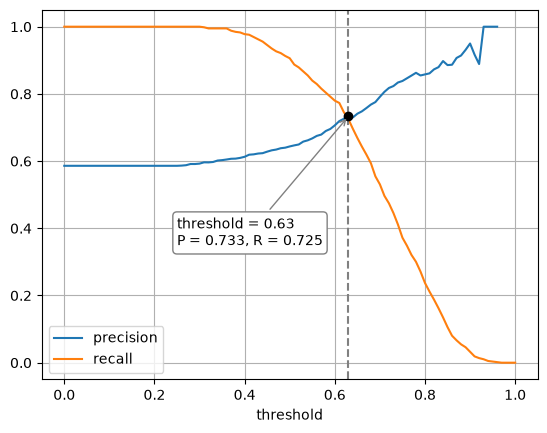

In [23]:
df_scores['diff'] = (df_scores.precision - df_scores.recall).abs() # calculate the value that intersect
valid = df_scores[df_scores.recall > 0]
best = valid.loc[valid['diff'].idxmin()]

ax = df_scores.plot(x='threshold', y=['precision', 'recall'], grid=True) # dataframe [precision,recall]
ax.axvline(best.threshold, color='gray', linestyle='--') # -- intersection
ax.plot(best.threshold, best.precision, 'ko')
ax.annotate(f'threshold = {best.threshold:.2f}\nP = {best.precision:.3f}, R = {best.recall:.3f}', # annotate position
            xy=(best.threshold, best.precision), xytext=(0.25, 0.35),
            arrowprops=dict(arrowstyle='->', color='gray'),
            bbox=dict(boxstyle='round', fc='white', ec='gray'))
plt.show()

## Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01


In [24]:
P, R = df_scores.precision, df_scores.recall
df_scores['f1'] = (2 * P * R / (P + R)).fillna(0)

At which threshold F1 is maximal?

In [25]:
df_scores['f1'].idxmax()

41

In [26]:
best_idx = df_scores['f1'].idxmax()

(df_scores.loc[best_idx - 5 : best_idx + 5, ['threshold', 'precision', 'recall', 'f1']]
   .style
   .format(precision=3)
   .background_gradient(cmap='Blues', subset=['f1'])
   .highlight_max(subset=['f1'], color='gold'))


,threshold,precision,recall,f1
36,0.360,0.605,0.995,0.752
37,0.370,0.607,0.988,0.752
38,0.380,0.607,0.985,0.751
39,0.390,0.610,0.983,0.752
40,0.400,0.613,0.978,0.753
41,0.410,0.619,0.976,0.758
42,0.420,0.620,0.969,0.756
43,0.430,0.623,0.962,0.756
44,0.440,0.624,0.956,0.755
45,0.450,0.628,0.945,0.755


The maximal threshold for F1 (with `0.758`) is `0.410`.

## Question 5: 5-Fold CV


Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

```
KFold(n_splits=5, shuffle=True, random_state=1)
```

* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

In [27]:
from sklearn.model_selection import KFold

In [28]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [ ]:
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train, C=1.0)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)
    print('\tC=%s \t|\t %.3f +- %.3f' % (1.0, np.mean(scores), np.std(scores)))

	C=1.0 	|	0.731 +- 0.000
	C=1.0 	|	0.730 +- 0.000
	C=1.0 	|	0.732 +- 0.003
	C=1.0 	|	0.734 +- 0.005
	C=1.0 	|	0.732 +- 0.007


In [50]:
df_folds = pd.DataFrame({'fold': range(1, 6), 'auc': scores})
df_folds['std'] = df_folds['auc'].expanding().std(ddof=0).round(3)

(df_folds.style
   .hide(axis='index')
   .format({'auc': '{:.3f}', 'std': '{:.4f}'})
   .background_gradient(cmap='Blues', subset=['auc', 'std']))


fold,auc,std
1,0.731,0.0000
2,0.730,0.0000
3,0.736,0.0030
4,0.741,0.0050
5,0.721,0.0070


In [51]:
print(f'mean = {np.mean(scores):.3f}, std = {np.std(scores):.3f}')

mean = 0.732, std = 0.007


The standard desviation of the scores across different folds with `0.007`.

## Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter `C`

* Iterate over the following `C` values: `[0.000001, 0.001, 1]`
* Initialize `KFold` with the same parameters as previously
* Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
* Compute the mean ROC AUC as well as the std (round the mean and std to 3
  decimal digits).

Which `C` leads to the best mean ROC AUC?

In [52]:
from tqdm.auto import tqdm

In [57]:
results = []

for C in tqdm([0.000001, 0.001, 1]):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        scores.append(roc_auc_score(y_val, y_pred))

    results.append((C, round(np.mean(scores), 3), round(np.std(scores), 3)))
    print('\tC=%s\t|\t%.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/3 [00:00<?, ?it/s]

	C=1e-06	|	0.617 +- 0.019
	C=0.001	|	0.749 +- 0.010
	C=1	|	0.732 +- 0.007


In [60]:
df_c = pd.DataFrame(results, columns=['C', 'mean_auc', 'std'])

(df_c.style
   .hide(axis='index')
   .format({'C': '{:g}', 'mean_auc': '{:.3f}', 'std': '{:.3f}'})
   .background_gradient(cmap='Blues', subset=['mean_auc'])
   .background_gradient(cmap='Oranges', subset=['std'])
    .highlight_max(subset=['mean_auc'], props='background-color: gold; color: black; font-weight: bold'))

C,mean_auc,std
1e-06,0.617,0.019
0.001,0.749,0.010
1,0.732,0.007


The `C` value that leads the best mean ROC_AUC is `0.001`.